In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    hamming_loss, accuracy_score, f1_score, precision_score,
    recall_score, classification_report,
)

warnings.filterwarnings("ignore")

In [2]:
CSV_PATH = "netflix_titles.csv"
OUTPUT_TARGET = "netflix_multilabel_target.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.2
MIN_LABEL_COUNT = 150

In [3]:
GENRE_MAP = {
    # Drama
    "Dramas": "Drama", "TV Dramas": "Drama",
    # Comedy
    "Comedies": "Comedy", "TV Comedies": "Comedy",
    # Action & Adventure
    "Action & Adventure": "Action & Adventure",
    "TV Action & Adventure": "Action & Adventure",
    # Documentary
    "Documentaries": "Documentary", "Docuseries": "Documentary",
    "Science & Nature TV": "Documentary",
    # Romance
    "Romantic Movies": "Romance", "Romantic TV Shows": "Romance",
    # Thriller / Crime / Mystery
    "Thrillers": "Thriller", "TV Thrillers": "Thriller",
    "Crime TV Shows": "Crime", "TV Mysteries": "Crime",
    # Horror
    "Horror Movies": "Horror", "TV Horror": "Horror",
    # Sci-Fi & Fantasy
    "Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    "TV Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    # Anak & Keluarga
    "Children & Family Movies": "Kids & Family", "Kids' TV": "Kids & Family",
    "Teen TV Shows": "Kids & Family",
    # Musik
    "Music & Musicals": "Music",
    # Reality
    "Reality TV": "Reality",
    # Stand-up
    "Stand-Up Comedy": "Stand-Up & Talk Show",
    "Stand-Up Comedy & Talk Shows": "Stand-Up & Talk Show",
    # Olahraga
    "Sports Movies": "Sports",
    # Anime
    "Anime Series": "Anime", "Anime Features": "Anime",
    # Lainnya
    "LGBTQ Movies": "LGBTQ",
    "Faith & Spirituality": "Faith & Spirituality",
}

In [4]:
def buat_target(listed_in: str):
    """Ubah string listed_in menjadi daftar genre unik yang sudah dinormalisasi."""
    labels = []
    for g in str(listed_in).split(","):
        g = g.strip()
        if g in GENRE_MAP and GENRE_MAP[g] not in labels:
            labels.append(GENRE_MAP[g])
    return labels

In [5]:
print("=" * 70)
print("1. LOAD DATA")
print("=" * 70)
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"File '{CSV_PATH}' tidak ditemukan. Taruh di folder yang sama "
        "dengan script ini, atau ubah CSV_PATH."
    )

1. LOAD DATA


In [6]:
df = pd.read_csv(CSV_PATH)
print("Ukuran data awal :", df.shape)
print("Kolom            :", list(df.columns))

Ukuran data awal : (8807, 12)
Kolom            : ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [7]:
rating_valid = {
    "TV-MA", "TV-14", "TV-PG", "R", "PG-13", "TV-Y7", "TV-Y", "PG",
    "TV-G", "NR", "G", "TV-Y7-FV", "NC-17", "UR",
}
df["rating"] = df["rating"].where(df["rating"].isin(rating_valid), "Unknown")
df["description"] = df["description"].fillna("")

In [8]:
df["labels"] = df["listed_in"].apply(buat_target)

# Hitung frekuensi label, buang label yang terlalu jarang
from collections import Counter
cnt = Counter(l for ls in df["labels"] for l in ls)
label_dipakai = sorted([l for l, c in cnt.items() if c >= MIN_LABEL_COUNT])
df["labels"] = df["labels"].apply(lambda ls: [l for l in ls if l in label_dipakai])

In [9]:
df = df[df["labels"].apply(len) > 0].reset_index(drop=True)
print("Ukuran data final:", df.shape)

mlb = MultiLabelBinarizer(classes=label_dipakai)
Y = mlb.fit_transform(df["labels"])
label_names = list(mlb.classes_)

print("\nJumlah label target :", len(label_names))
print("Rata-rata label/judul:", round(Y.sum(axis=1).mean(), 2))
print("\nDistribusi label:")
dist = pd.Series(Y.sum(axis=0), index=label_names).sort_values(ascending=False)
print(dist.to_string())

Ukuran data final: (8725, 13)

Jumlah label target : 15
Rata-rata label/judul: 1.53

Distribusi label:
Drama                   3190
Comedy                  2255
Documentary             1268
Kids & Family           1157
Action & Adventure      1027
Romance                  986
Thriller                 634
Crime                    545
Horror                   432
Stand-Up & Talk Show     399
Music                    375
Sci-Fi & Fantasy         327
Reality                  255
Anime                    247
Sports                   219


In [10]:
target_df = pd.DataFrame(Y, columns=label_names)
target_out = pd.concat(
    [df[["show_id", "title", "type", "rating", "description"]],
     df["labels"].apply(lambda x: ", ".join(x)).rename("genre_labels"),
     target_df],
    axis=1,
)
target_out.to_csv(OUTPUT_TARGET, index=False, encoding="utf-8-sig")
print(f"\n[OK] Data target disimpan ke: {OUTPUT_TARGET}")
print(target_out[["title", "genre_labels"]].head(5).to_string(index=False))


[OK] Data target disimpan ke: netflix_multilabel_target.csv
                title              genre_labels
 Dick Johnson Is Dead               Documentary
        Blood & Water              Drama, Crime
            Ganglands Crime, Action & Adventure
Jailbirds New Orleans      Documentary, Reality
         Kota Factory           Romance, Comedy


In [11]:
print("\n" + "=" * 70)
print("2. EKSTRAKSI FITUR")
print("=" * 70)

idx = np.arange(len(df))
idx_train, idx_test = train_test_split(
    idx, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

tfidf = TfidfVectorizer(
    stop_words="english", max_features=8000, ngram_range=(1, 2), min_df=2,
    sublinear_tf=True,
)
ohe = OneHotEncoder(handle_unknown="ignore")

X_text_train = tfidf.fit_transform(df.loc[idx_train, "description"])
X_text_test = tfidf.transform(df.loc[idx_test, "description"])

X_cat_train = ohe.fit_transform(df.loc[idx_train, ["type", "rating"]])
X_cat_test = ohe.transform(df.loc[idx_test, ["type", "rating"]])

X_train = hstack([X_text_train, X_cat_train]).tocsr()
X_test = hstack([X_text_test, X_cat_test]).tocsr()
Y_train, Y_test = Y[idx_train], Y[idx_test]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Y_train:", Y_train.shape, "| Y_test:", Y_test.shape)


2. EKSTRAKSI FITUR
X_train: (6980, 8017) | X_test: (1745, 8017)
Y_train: (6980, 15) | Y_test: (1745, 15)


In [12]:
print("\n" + "=" * 70)
print("3. PELATIHAN MODEL (One-vs-Rest)")
print("=" * 70)

models = {
    "Logistic Regression": OneVsRestClassifier(
        LogisticRegression(max_iter=1000, C=4, class_weight="balanced"),
        n_jobs=-1,
    ),
    "Linear SVM": OneVsRestClassifier(
        LinearSVC(C=0.5, class_weight="balanced"), n_jobs=-1,
    ),
}

hasil = {}
for nama, model in models.items():
    print(f"Melatih {nama} ...")
    model.fit(X_train, Y_train)
    hasil[nama] = model.predict(X_test)


3. PELATIHAN MODEL (One-vs-Rest)
Melatih Logistic Regression ...
Melatih Linear SVM ...


In [13]:
print("\n" + "=" * 70)
print("4. EVALUASI")
print("=" * 70)

ringkasan = []
for nama, Y_pred in hasil.items():
    ringkasan.append({
        "Model": nama,
        "Hamming Loss": hamming_loss(Y_test, Y_pred),
        "Subset Accuracy": accuracy_score(Y_test, Y_pred),
        "Precision (micro)": precision_score(Y_test, Y_pred, average="micro", zero_division=0),
        "Recall (micro)": recall_score(Y_test, Y_pred, average="micro", zero_division=0),
        "F1 (micro)": f1_score(Y_test, Y_pred, average="micro", zero_division=0),
        "F1 (macro)": f1_score(Y_test, Y_pred, average="macro", zero_division=0),
        "F1 (samples)": f1_score(Y_test, Y_pred, average="samples", zero_division=0),
    })
ringkasan_df = pd.DataFrame(ringkasan).set_index("Model").round(4)
print(ringkasan_df.T.to_string())

model_terbaik = ringkasan_df["F1 (micro)"].idxmax()
print(f"\nModel terbaik (F1 micro): {model_terbaik}")
print("\nLaporan per label -", model_terbaik)
print(classification_report(
    Y_test, hasil[model_terbaik], target_names=label_names, zero_division=0
))


4. EVALUASI
Model              Logistic Regression  Linear SVM
Hamming Loss                    0.0840      0.0823
Subset Accuracy                 0.2934      0.3026
Precision (micro)               0.5761      0.5881
Recall (micro)                  0.6667      0.6453
F1 (micro)                      0.6181      0.6154
F1 (macro)                      0.5785      0.5846
F1 (samples)                    0.6163      0.6099

Model terbaik (F1 micro): Logistic Regression

Laporan per label - Logistic Regression
                      precision    recall  f1-score   support

  Action & Adventure       0.51      0.64      0.57       210
               Anime       0.45      0.50      0.47        46
              Comedy       0.56      0.58      0.57       470
               Crime       0.54      0.84      0.66       103
         Documentary       0.75      0.79      0.77       251
               Drama       0.63      0.71      0.67       647
              Horror       0.46      0.62      0.53     

[OK] Grafik disimpan ke: hasil_multilabel_netflix.png


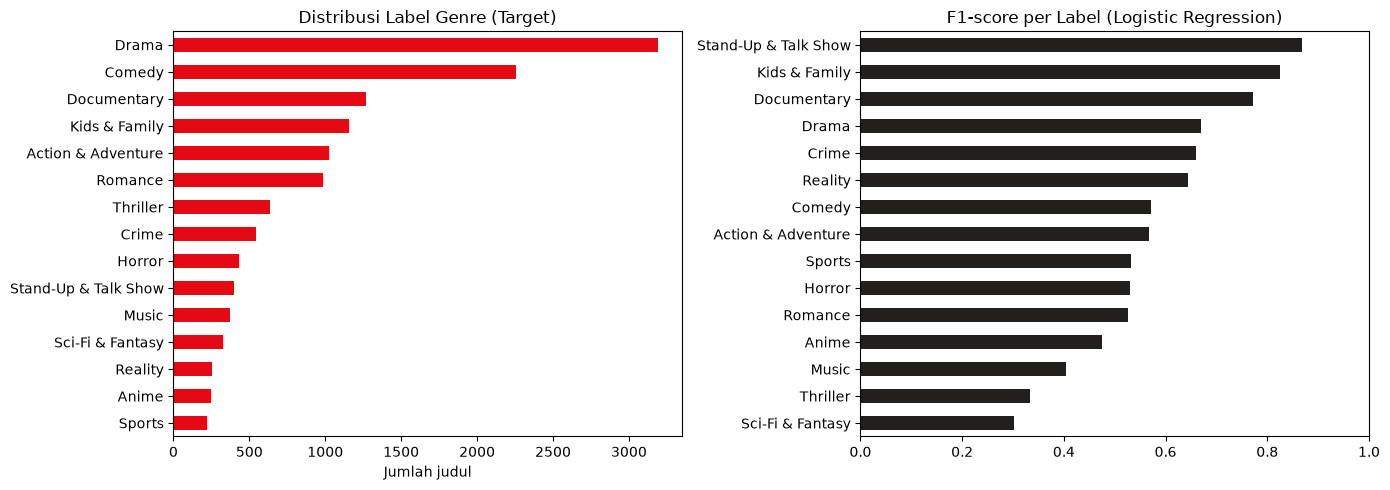

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

dist.sort_values().plot(kind="barh", ax=ax[0], color="#e50914")
ax[0].set_title("Distribusi Label Genre (Target)")
ax[0].set_xlabel("Jumlah judul")

f1_label = f1_score(Y_test, hasil[model_terbaik], average=None, zero_division=0)
pd.Series(f1_label, index=label_names).sort_values().plot(
    kind="barh", ax=ax[1], color="#221f1f"
)
ax[1].set_title(f"F1-score per Label ({model_terbaik})")
ax[1].set_xlim(0, 1)

plt.tight_layout()
plt.savefig("hasil_multilabel_netflix.png", dpi=150)
print("[OK] Grafik disimpan ke: hasil_multilabel_netflix.png")
plt.show()

In [15]:
print("\n" + "=" * 70)
print("5. CONTOH PREDIKSI")
print("=" * 70)

best = models[model_terbaik]


def prediksi(deskripsi: str, tipe: str = "Movie", rating: str = "PG-13"):
    xt = tfidf.transform([deskripsi])
    xc = ohe.transform(pd.DataFrame([[tipe, rating]], columns=["type", "rating"]))
    pred = best.predict(hstack([xt, xc]).tocsr())[0]
    hasil_label = [l for l, p in zip(label_names, pred) if p == 1]
    return hasil_label or ["(tidak ada label terprediksi)"]


contoh = [
    ("A detective hunts a serial killer terrorizing a small town.", "TV Show", "TV-MA"),
    ("Two best friends embark on a hilarious road trip to find true love.", "Movie", "PG-13"),
    ("A young wizard battles dark creatures to save a magical kingdom.", "Movie", "PG"),
]
for desk, t, r in contoh:
    print(f"- {desk}\n  -> {prediksi(desk, t, r)}")


5. CONTOH PREDIKSI
- A detective hunts a serial killer terrorizing a small town.
  -> ['Crime', 'Drama', 'Thriller']
- Two best friends embark on a hilarious road trip to find true love.
  -> ['Comedy', 'Drama', 'Romance']
- A young wizard battles dark creatures to save a magical kingdom.
  -> ['Action & Adventure', 'Anime', 'Kids & Family']
